# BeeSafe AI — Phase 08 (Revised): Scientific Validation, Calibration & BeeToxAI External-Data Audit

**Purpose:** validate the integrity of prior-phase artifacts, assess grouped cross-fitted calibration, quantify uncertainty, and add a carefully gated optional evaluation on a genuinely independent external dataset.


## Cell 1 — Imports and reproducibility settings

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, fbeta_score,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix
)
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
N_OUTER = 4
N_INNER = 3
BOOTSTRAP_REPLICATES = int(os.environ.get("BEESAFE_P08_BOOTSTRAPS", "500"))
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 80)
sns.set_theme(style="whitegrid")
print("BeeSafe AI — Phase 08: Scientific Validation & Calibration")
print("NumPy:", np.__version__, "Pandas:", pd.__version__)
print("Group-bootstrap replicates:", BOOTSTRAP_REPLICATES)

BeeSafe AI — Phase 08: Scientific Validation & Calibration
NumPy: 2.5.2 Pandas: 3.0.5
Group-bootstrap replicates: 500


## Cell 2 — Define project paths and require earlier-phase artifacts

In [2]:
DEFAULT_ROOT = Path(r"E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI")
PROJECT_ROOT = Path(os.environ.get("BEESAFE_PROJECT_ROOT", str(DEFAULT_ROOT)))
PHASE03_DIR = PROJECT_ROOT / "data" / "processed" / "phase03"
PHASE05_DIR = PROJECT_ROOT / "reports" / "model_optimization_advanced"
PHASE06_DIR = PROJECT_ROOT / "reports" / "explainability_reliability"
PHASE07_DIR = PROJECT_ROOT / "reports" / "robustness_validation_phase07"
MODEL_DIR = PROJECT_ROOT / "models"
EXTERNAL_DIR = PROJECT_ROOT / "data" / "external"
EXTERNAL_RAW_DIR = EXTERNAL_DIR / "raw"
BEETOXAI_S1_PATH = EXTERNAL_RAW_DIR / "1-s2.0-S2667318521000131-mmc1.csv"
BEETOXAI_S2_PATH = EXTERNAL_RAW_DIR / "1-s2.0-S2667318521000131-mmc2.csv"
SOURCE_CSV_PATH = PROJECT_ROOT / "data" / "raw" / "dataset_final.csv"
EXTERNAL_PATH = EXTERNAL_DIR / "external_honeybee_acute.csv"
EXTERNAL_TEMPLATE_PATH = EXTERNAL_DIR / "external_honeybee_acute_TEMPLATE.csv"
EXTERNAL_README_PATH = EXTERNAL_DIR / "README_external_validation.md"
REPORT_DIR = PROJECT_ROOT / "reports" / "scientific_validation_phase08"
FIGURE_DIR = REPORT_DIR / "figures"
TABLE_DIR = REPORT_DIR / "tables"

FEATURES_PATH = PHASE03_DIR / "03_baseline_features.npz"
METADATA_PATH = PHASE03_DIR / "03_baseline_metadata.csv"
MODEL_PATH = MODEL_DIR / "05_advanced_tuned_candidate.joblib"
OOF_PATH = PHASE05_DIR / "05_nested_cv_oof_predictions.csv"
PHASE05_SUMMARY_PATH = PHASE05_DIR / "05_advanced_optimization_summary.json"
PHASE06_AD_PATH = PHASE06_DIR / "tables" / "06_oof_applicability_domain.csv"
PHASE07_SUMMARY_PATH = PHASE07_DIR / "07_robustness_validation_summary.json"
EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)
for folder in [REPORT_DIR, FIGURE_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

required = {
    "Phase 03 features": FEATURES_PATH,
    "Phase 03 metadata": METADATA_PATH,
    "Phase 05 candidate model bundle": MODEL_PATH,
    "Phase 05 nested OOF predictions": OOF_PATH,
}
missing = [f"{label}: {path}" for label, path in required.items() if not path.is_file()]
if missing:
    raise FileNotFoundError("Required artifact(s) missing. Keep Phase 03 and Phase 05 files.\n- " + "\n- ".join(missing))
print("Project root:", PROJECT_ROOT)
print("Outputs:", REPORT_DIR)
print("Required inputs found.")
print("ApisTox source CSV:", SOURCE_CSV_PATH, "| exists:", SOURCE_CSV_PATH.is_file())
print("BeeToxAI S1 contact CSV:", BEETOXAI_S1_PATH, "| exists:", BEETOXAI_S1_PATH.is_file())
print("BeeToxAI S2 oral CSV:", BEETOXAI_S2_PATH, "| exists:", BEETOXAI_S2_PATH.is_file())
print("BeeToxAI files are audited, but external scoring will be gated by overlap, sample size, and provenance/endpoint review.")

Project root: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI
Outputs: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\scientific_validation_phase08
Required inputs found.
ApisTox source CSV: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\raw\dataset_final.csv | exists: True
BeeToxAI S1 contact CSV: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\external\raw\1-s2.0-S2667318521000131-mmc1.csv | exists: True
BeeToxAI S2 oral CSV: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\external\raw\1-s2.0-S2667318521000131-mmc2.csv | exists: True
BeeToxAI files are audited, but external scoring will be gated by overlap, sample size, and provenance/endpoint review.


## Cell 3 — Load and integrity-check data, candidate model, and saved folds

In [3]:
with np.load(FEATURES_PATH, allow_pickle=False) as z:
    X_desc = z["X_descriptors"].astype(np.float64, copy=True)
    X_morgan = z["X_morgan"].astype(np.uint8, copy=True)
    y = z["y_binary"].astype(np.int64, copy=True)
    row_ids = z["source_row_index"].astype(np.int64, copy=True)
    descriptor_names = z["descriptor_names"].astype(str).tolist()
metadata = pd.read_csv(METADATA_PATH)
oof = pd.read_csv(OOF_PATH)
bundle = joblib.load(MODEL_PATH)
phase05_summary = json.loads(PHASE05_SUMMARY_PATH.read_text(encoding="utf-8")) if PHASE05_SUMMARY_PATH.exists() else {}
phase07_summary = json.loads(PHASE07_SUMMARY_PATH.read_text(encoding="utf-8")) if PHASE07_SUMMARY_PATH.exists() else {}

required_meta = {"source_row_index", "name", "CID", "CAS", "SMILES", "label", "structure_group", "review_priority"}
required_oof = {"source_row_index", "outer_fold", "y_true", "oof_probability", "selected_family_in_fold"}
if required_meta - set(metadata.columns):
    raise ValueError(f"Phase 03 metadata missing: {sorted(required_meta - set(metadata.columns))}")
if required_oof - set(oof.columns):
    raise ValueError(f"Phase 05 OOF file missing: {sorted(required_oof - set(oof.columns))}")
if not (len(row_ids) == len(y) == len(metadata) == len(X_desc) == len(X_morgan)):
    raise ValueError("Feature, target, row-ID and metadata lengths do not match.")
if not np.array_equal(row_ids, metadata["source_row_index"].to_numpy(dtype=np.int64)):
    raise ValueError("Phase 03 NPZ row IDs are not aligned with metadata.")
if not np.array_equal(y, metadata["label"].to_numpy(dtype=int)):
    raise ValueError("Phase 03 labels do not match metadata labels.")
if metadata["source_row_index"].duplicated().any() or metadata["structure_group"].isna().any():
    raise ValueError("Duplicate row IDs or missing structure groups were found.")
if not metadata["review_priority"].astype(str).eq("NONE").all():
    raise ValueError("Conservative Phase 03 baseline contains records flagged for identity review.")
if not np.isin(X_morgan, [0, 1]).all() or not np.isfinite(X_desc).all():
    raise ValueError("Phase 03 features contain invalid values.")
if oof["source_row_index"].duplicated().any():
    raise ValueError("Nested OOF file should contain one row per source_row_index.")
if set(oof["source_row_index"].astype(int)) != set(metadata["source_row_index"].astype(int)):
    raise ValueError("Phase 05 OOF record IDs do not match the conservative Phase 03 baseline.")
if not np.array_equal(oof.sort_values("source_row_index")["y_true"].to_numpy(dtype=int), metadata.set_index("source_row_index").loc[oof.sort_values("source_row_index")["source_row_index"], "label"].to_numpy(dtype=int)):
    raise ValueError("Phase 05 OOF labels do not align with Phase 03 metadata.")
if "model" not in bundle or "feature_type" not in bundle:
    raise ValueError("Model bundle must include 'model' and 'feature_type'.")
if bundle["feature_type"] not in {"morgan", "descriptors"}:
    raise ValueError(f"Unsupported candidate feature type: {bundle['feature_type']}")

X = X_morgan if bundle["feature_type"] == "morgan" else X_desc
if X.shape[1] != getattr(bundle["model"], "n_features_in_", X.shape[1]):
    raise ValueError("Candidate model feature count does not match the selected Phase 03 feature matrix.")
if not np.isfinite(oof["oof_probability"].to_numpy(dtype=float)).all():
    raise ValueError("OOF predictions include NaN or infinite probabilities.")
if not oof["oof_probability"].between(0, 1).all():
    raise ValueError("OOF probabilities must be between 0 and 1.")

metadata = metadata.reset_index(drop=True)
row_to_pos = {int(r): i for i, r in enumerate(row_ids)}
oof["source_row_index"] = oof["source_row_index"].astype(int)
oof["outer_fold"] = oof["outer_fold"].astype(int)
oof = oof.merge(metadata[["source_row_index", "structure_group", "label", "review_priority"]], on="source_row_index", how="left", validate="one_to_one", suffixes=("", "_meta"))
if not np.array_equal(oof["y_true"].to_numpy(dtype=int), oof["label"].to_numpy(dtype=int)):
    raise ValueError("OOF and metadata labels differ.")

model_family = str(bundle.get("model_family", type(bundle["model"]).__name__))
print("Records:", len(metadata), "| Feature matrix:", X.shape)
print("Candidate family:", model_family, "| Feature type:", bundle["feature_type"])
print("Nested folds:", sorted(oof["outer_fold"].unique().tolist()))
print("Phase 05 selected threshold (raw scale; NOT automatically reused):", bundle.get("threshold"))
print("Prior phase OOF AP:", phase05_summary.get("nested_cv_mean_ap", "not recorded"))

Records: 1025 | Feature matrix: (1025, 2048)
Candidate family: Extra Trees — Morgan | Feature type: morgan
Nested folds: [1, 2, 3, 4]
Phase 05 selected threshold (raw scale; NOT automatically reused): 0.2556186777264476
Prior phase OOF AP: 0.75482672672048


## Cell 4 — Check group and fold integrity

In [4]:
groups = metadata["structure_group"].astype(str).to_numpy()
fold_assignment = oof.set_index("source_row_index")["outer_fold"].to_dict()
fold_for_position = np.array([int(fold_assignment[int(r)]) for r in row_ids], dtype=int)
fold_integrity_rows = []
for fold in sorted(np.unique(fold_for_position)):
    test_idx = np.flatnonzero(fold_for_position == fold)
    train_idx = np.flatnonzero(fold_for_position != fold)
    overlap = set(groups[train_idx]) & set(groups[test_idx])
    fold_integrity_rows.append({
        "outer_fold": int(fold), "train_records": len(train_idx), "evaluation_records": len(test_idx),
        "train_groups": len(set(groups[train_idx])), "evaluation_groups": len(set(groups[test_idx])),
        "overlapping_groups": len(overlap), "evaluation_toxic_prevalence": float(y[test_idx].mean())
    })
fold_integrity = pd.DataFrame(fold_integrity_rows)
display(fold_integrity)
if (fold_integrity["overlapping_groups"] != 0).any():
    raise ValueError("Structure-group overlap detected between existing Phase 05 folds.")
if set(fold_for_position) != set(oof["outer_fold"].unique()):
    raise ValueError("Fold assignment mismatch.")
fold_integrity.to_csv(TABLE_DIR / "08_fold_integrity.csv", index=False, encoding="utf-8-sig")
print("Group integrity passed for saved Phase 05 outer folds.")

,outer_fold,train_records,evaluation_records,train_groups,evaluation_groups,overlapping_groups,evaluation_toxic_prevalence
0,1,769,256,483,83,0,0.285156
1,2,769,256,403,163,0,0.289062
2,3,768,257,401,165,0,0.287938
3,4,769,256,411,155,0,0.285156


Group integrity passed for saved Phase 05 outer folds.


## Cell 5 — Baseline calibration and discrimination metrics

In [5]:
def expected_calibration_error(y_true, p, n_bins=10):
    y_true = np.asarray(y_true, dtype=int); p = np.asarray(p, dtype=float)
    # Equal-count bins; stable ordering makes bin membership deterministic.
    order = np.argsort(p, kind="mergesort")
    bins = np.array_split(order, min(n_bins, len(order)))
    rows = []
    for i, ix in enumerate(bins):
        if len(ix) == 0: continue
        mean_p = float(np.mean(p[ix])); observed = float(np.mean(y_true[ix]))
        rows.append({"bin": i+1, "n": len(ix), "mean_predicted": mean_p, "observed_fraction": observed,
                     "absolute_gap": abs(mean_p-observed)})
    tab = pd.DataFrame(rows)
    ece = float(np.average(tab["absolute_gap"], weights=tab["n"]))
    return ece, tab

def metric_row(y_true, p, pred=None, name="model"):
    p = np.clip(np.asarray(p, dtype=float), 1e-8, 1-1e-8)
    out = {"method": name, "n": len(y_true), "prevalence": float(np.mean(y_true)),
           "average_precision": float(average_precision_score(y_true, p)),
           "roc_auc": float(roc_auc_score(y_true, p)),
           "brier_score": float(brier_score_loss(y_true, p)),
           "log_loss": float(log_loss(y_true, p, labels=[0,1])),
           "ece_10_equal_count_bins": expected_calibration_error(y_true, p, n_bins=10)[0]}
    if pred is not None:
        pred = np.asarray(pred, dtype=int)
        out.update({"precision_toxic_at_0.50": precision_score(y_true, pred, zero_division=0),
                    "recall_toxic_at_0.50": recall_score(y_true, pred, zero_division=0),
                    "f1_toxic_at_0.50": f1_score(y_true, pred, zero_division=0),
                    "f2_toxic_at_0.50": fbeta_score(y_true, pred, beta=2, zero_division=0),
                    "mcc_at_0.50": matthews_corrcoef(y_true, pred)})
    return out

oof_sorted = oof.sort_values("source_row_index").reset_index(drop=True)
y_oof = oof_sorted["y_true"].to_numpy(dtype=int)
p_oof = oof_sorted["oof_probability"].to_numpy(dtype=float)
raw_metrics = metric_row(y_oof, p_oof, pred=(p_oof >= 0.5).astype(int), name="Phase05 nested OOF — raw probabilities")
print("Previously saved raw nested OOF metrics (reference, not refit):")
display(pd.DataFrame([raw_metrics]).round(4))
raw_bins_ece, raw_bins = expected_calibration_error(y_oof, p_oof, n_bins=10)
raw_bins.to_csv(TABLE_DIR / "08_raw_oof_calibration_bins.csv", index=False, encoding="utf-8-sig")

Previously saved raw nested OOF metrics (reference, not refit):


,method,n,prevalence,average_precision,roc_auc,brier_score,log_loss,ece_10_equal_count_bins,precision_toxic_at_0.50,recall_toxic_at_0.50,f1_toxic_at_0.50,f2_toxic_at_0.50,mcc_at_0.50
0,Phase05 nested OOF — raw probabilities,1025,0.2868,0.7391,0.8174,0.1358,0.4362,0.0586,0.7778,0.5952,0.6744,0.6246,0.5757


## Cell 6 — Define calibration helpers and grouped calibration workflow

In [6]:
def fit_calibrator(method, calibration_prob, y_cal):
    calibration_prob = np.asarray(calibration_prob, dtype=float)
    y_cal = np.asarray(y_cal, dtype=int)
    if len(np.unique(y_cal)) < 2:
        raise ValueError("Calibration fold contains only one class; grouped split configuration must be revised.")
    if method == "sigmoid":
        # Platt-style calibration on log-odds of the estimator's probability.
        eps = 1e-6
        pclip = np.clip(calibration_prob, eps, 1-eps)
        logit = np.log(pclip / (1-pclip)).reshape(-1, 1)
        calibrator = LogisticRegression(C=1e3, solver="lbfgs", max_iter=2000, random_state=RANDOM_STATE)
        calibrator.fit(logit, y_cal)
        return calibrator
    if method == "isotonic":
        calibrator = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
        calibrator.fit(calibration_prob, y_cal)
        return calibrator
    raise ValueError(f"Unknown calibration method: {method}")

def apply_calibrator(calibrator, method, probability):
    probability = np.asarray(probability, dtype=float)
    if method == "sigmoid":
        eps = 1e-6
        pclip = np.clip(probability, eps, 1-eps)
        logit = np.log(pclip / (1-pclip)).reshape(-1, 1)
        return calibrator.predict_proba(logit)[:, 1]
    return np.asarray(calibrator.predict(probability), dtype=float).clip(0, 1)

print("Calibration methods: sigmoid (predeclared default) and isotonic (comparison).")
print("Calibration workflow: each outer fold is evaluated only after model and calibrator fitting on its other folds.")

Calibration methods: sigmoid (predeclared default) and isotonic (comparison).
Calibration workflow: each outer fold is evaluated only after model and calibrator fitting on its other folds.


## Cell 7 — Grouped cross-fitted calibration evaluation

**Interpretation boundary:** this estimates a fixed, previously selected candidate plus a grouped calibration procedure; it is not an independent external validation.

In [7]:
# For each saved outer fold, hold that fold aside. Within the remaining rows, each inner
# model is fitted on inner-training groups and calibrated on separate calibration groups.
# Its calibrated predictions are evaluated only on the untouched outer fold.
calibrated_oof_parts = []
calibration_fold_log = []
outer_values = sorted(np.unique(fold_for_position).tolist())
for outer_fold in outer_values:
    outer_test_idx = np.flatnonzero(fold_for_position == outer_fold)
    outer_train_idx = np.flatnonzero(fold_for_position != outer_fold)
    X_train, y_train, g_train = X[outer_train_idx], y[outer_train_idx], groups[outer_train_idx]
    X_test, y_test = X[outer_test_idx], y[outer_test_idx]
    inner_cv = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=RANDOM_STATE + 1000 + int(outer_fold))
    fold_raw, fold_sig, fold_iso = [], [], []
    inner_rows = list(inner_cv.split(X_train, y_train, groups=g_train))
    for inner_fold, (fit_rel, cal_rel) in enumerate(inner_rows, start=1):
        if set(g_train[fit_rel]) & set(g_train[cal_rel]):
            raise ValueError(f"Inner group leakage in outer fold {outer_fold}, inner fold {inner_fold}.")
        if len(np.unique(y_train[fit_rel])) < 2 or len(np.unique(y_train[cal_rel])) < 2:
            raise ValueError("An inner fit/calibration split lacks one class. Reduce fold count or inspect groups.")
        estimator = clone(bundle["model"])
        estimator.fit(X_train[fit_rel], y_train[fit_rel])
        p_cal = estimator.predict_proba(X_train[cal_rel])[:, 1]
        p_test = estimator.predict_proba(X_test)[:, 1]
        sig_cal = fit_calibrator("sigmoid", p_cal, y_train[cal_rel])
        iso_cal = fit_calibrator("isotonic", p_cal, y_train[cal_rel])
        fold_raw.append(p_test)
        fold_sig.append(apply_calibrator(sig_cal, "sigmoid", p_test))
        fold_iso.append(apply_calibrator(iso_cal, "isotonic", p_test))
        calibration_fold_log.append({"outer_fold": int(outer_fold), "inner_fold": inner_fold,
                                     "base_fit_records": int(len(fit_rel)), "calibration_records": int(len(cal_rel)),
                                     "outer_evaluation_records": int(len(outer_test_idx)),
                                     "base_model_family": model_family, "calibration_method": "sigmoid_and_isotonic"})
    part = pd.DataFrame({
        "source_row_index": row_ids[outer_test_idx], "outer_fold": int(outer_fold),
        "y_true": y_test,
        "raw_probability_phase08": np.mean(fold_raw, axis=0),
        "sigmoid_calibrated_probability": np.mean(fold_sig, axis=0),
        "isotonic_calibrated_probability": np.mean(fold_iso, axis=0),
        "structure_group": groups[outer_test_idx],
    })
    calibrated_oof_parts.append(part)
    print(f"Outer fold {outer_fold}: evaluated {len(outer_test_idx)} records; calibration fitted only inside outer-training records.")

calibrated_oof = pd.concat(calibrated_oof_parts, ignore_index=True).sort_values("source_row_index").reset_index(drop=True)
if calibrated_oof["source_row_index"].duplicated().any() or len(calibrated_oof) != len(metadata):
    raise ValueError("Cross-fitted calibrated predictions are not a one-time partition of the baseline records.")
if set(calibrated_oof["source_row_index"]) != set(metadata["source_row_index"]):
    raise ValueError("Calibrated OOF predictions do not cover all baseline source rows.")
if not np.array_equal(calibrated_oof["y_true"].to_numpy(dtype=int), metadata.set_index("source_row_index").loc[calibrated_oof["source_row_index"], "label"].to_numpy(dtype=int)):
    raise ValueError("Cross-fitted calibrated predictions are not aligned with labels.")
calibrated_oof.to_csv(TABLE_DIR / "08_cross_fitted_calibrated_predictions.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(calibration_fold_log).to_csv(TABLE_DIR / "08_calibration_fold_log.csv", index=False, encoding="utf-8-sig")
display(calibrated_oof.head())

Outer fold 1: evaluated 256 records; calibration fitted only inside outer-training records.
Outer fold 2: evaluated 256 records; calibration fitted only inside outer-training records.
Outer fold 3: evaluated 257 records; calibration fitted only inside outer-training records.
Outer fold 4: evaluated 256 records; calibration fitted only inside outer-training records.


,source_row_index,outer_fold,y_true,raw_probability_phase08,sigmoid_calibrated_probability,isotonic_calibrated_probability,structure_group
0,0,2,0,0.084919,0.081646,0.086821,ACYCLIC:O=C(O)C(=O)O
1,1,1,0,0.552387,0.460846,0.469303,SCAFFOLD:c1ccccc1
2,2,4,0,0.081614,0.097945,0.099204,ACYCLIC:O=[Si]=O
3,3,1,0,0.137937,0.114536,0.121267,SCAFFOLD:c1ccccc1
4,4,1,1,0.068374,0.058965,0.072189,SCAFFOLD:O=S(=O)(c1ccccc1)c1ccccc1


## Cell 8 — Compare raw, sigmoid-calibrated, and isotonic-calibrated predictions

In [8]:
yc = calibrated_oof["y_true"].to_numpy(dtype=int)
metric_rows = []
for method, col in [
    ("raw grouped-calibration workflow", "raw_probability_phase08"),
    ("sigmoid calibrated", "sigmoid_calibrated_probability"),
    ("isotonic calibrated", "isotonic_calibrated_probability"),
]:
    pp = calibrated_oof[col].to_numpy(dtype=float)
    metric_rows.append(metric_row(yc, pp, pred=(pp >= 0.5).astype(int), name=method))
calibration_comparison = pd.DataFrame(metric_rows)
display(calibration_comparison.round(4))
calibration_comparison.to_csv(TABLE_DIR / "08_calibration_method_comparison.csv", index=False, encoding="utf-8-sig")

print("Interpretation: Brier score, log loss, ECE, AP and ROC-AUC answer different questions.")
print("The primary deployment default remains sigmoid unless a later preregistered evaluation supports a different choice.")

,method,n,prevalence,average_precision,roc_auc,brier_score,log_loss,ece_10_equal_count_bins,precision_toxic_at_0.50,recall_toxic_at_0.50,f1_toxic_at_0.50,f2_toxic_at_0.50,mcc_at_0.50
0,raw grouped-calibration workflow,1025,0.2868,0.7597,0.8253,0.1276,0.4203,0.0655,0.7902,0.6020,0.6834,0.6321,0.5885
1,sigmoid calibrated,1025,0.2868,0.7572,0.8254,0.1264,0.4181,0.0614,0.8634,0.5374,0.6625,0.5813,0.5943
2,isotonic calibrated,1025,0.2868,0.7548,0.8247,0.1229,0.4231,0.0478,0.8770,0.5578,0.6819,0.6016,0.6164


Interpretation: Brier score, log loss, ECE, AP and ROC-AUC answer different questions.
The primary deployment default remains sigmoid unless a later preregistered evaluation supports a different choice.


## Cell 9 — Calibration plots and probability-bin diagnostics

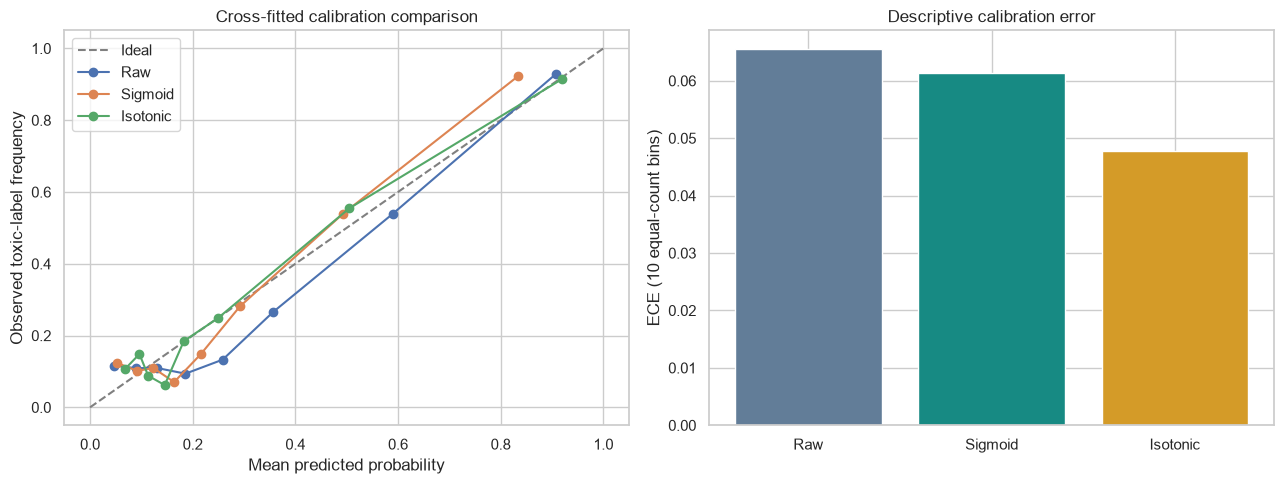

ECE is bin-dependent and descriptive; it is not a calibrated safety guarantee.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
for method, col in [("Raw", "raw_probability_phase08"), ("Sigmoid", "sigmoid_calibrated_probability"), ("Isotonic", "isotonic_calibrated_probability")]:
    frac_pos, mean_pred = calibration_curve(yc, calibrated_oof[col].to_numpy(dtype=float), n_bins=8, strategy="quantile")
    axes[0].plot(mean_pred, frac_pos, marker="o", label=method)
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Observed toxic-label frequency")
axes[0].set_title("Cross-fitted calibration comparison")
axes[0].legend()

sig_ece, sig_bins = expected_calibration_error(yc, calibrated_oof["sigmoid_calibrated_probability"], n_bins=10)
iso_ece, iso_bins = expected_calibration_error(yc, calibrated_oof["isotonic_calibrated_probability"], n_bins=10)
raw_ece, raw_bins = expected_calibration_error(yc, calibrated_oof["raw_probability_phase08"], n_bins=10)
axes[1].bar(["Raw", "Sigmoid", "Isotonic"], [raw_ece, sig_ece, iso_ece], color=["#627D98", "#178A83", "#D49B28"])
axes[1].set_ylabel("ECE (10 equal-count bins)")
axes[1].set_title("Descriptive calibration error")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_calibration_comparison.png", dpi=250, bbox_inches="tight")
plt.show()
for name, table in [("raw", raw_bins), ("sigmoid", sig_bins), ("isotonic", iso_bins)]:
    table.to_csv(TABLE_DIR / f"08_{name}_calibration_bins.csv", index=False, encoding="utf-8-sig")
print("ECE is bin-dependent and descriptive; it is not a calibrated safety guarantee.")

## Cell 10 — Fold-level calibration stability

,outer_fold,method,n,average_precision,roc_auc,brier_score,log_loss,ece_10_equal_count_bins
0,1,raw,256,0.8579,0.9133,0.1123,0.3756,0.1271
1,1,sigmoid,256,0.8531,0.9121,0.1025,0.3522,0.0938
2,1,isotonic,256,0.8372,0.9077,0.1000,0.3470,0.0818
3,2,raw,256,0.7431,0.7984,0.1361,0.4416,0.0631
4,2,sigmoid,256,0.7469,0.7969,0.1408,0.4533,0.0710
5,2,isotonic,256,0.7470,0.8058,0.1356,0.4358,0.0782
6,3,raw,257,0.6942,0.7837,0.1445,0.4740,0.0819
7,3,sigmoid,257,0.6917,0.7807,0.1422,0.4662,0.0563
8,3,isotonic,257,0.6748,0.7623,0.1437,0.5329,0.0702
9,4,raw,256,0.8044,0.8495,0.1172,0.3897,0.0720


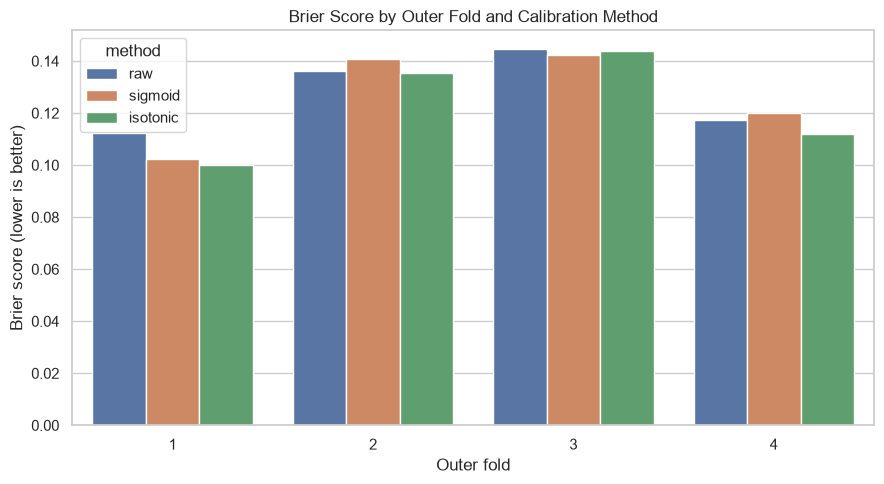

In [10]:
fold_calibration_rows = []
for fold, part in calibrated_oof.groupby("outer_fold", sort=True):
    yt = part["y_true"].to_numpy(dtype=int)
    for method, col in [("raw", "raw_probability_phase08"), ("sigmoid", "sigmoid_calibrated_probability"), ("isotonic", "isotonic_calibrated_probability")]:
        pp = np.clip(part[col].to_numpy(dtype=float), 1e-8, 1-1e-8)
        fold_calibration_rows.append({"outer_fold": int(fold), "method": method, "n": len(part),
            "average_precision": average_precision_score(yt, pp), "roc_auc": roc_auc_score(yt, pp),
            "brier_score": brier_score_loss(yt, pp), "log_loss": log_loss(yt, pp, labels=[0,1]),
            "ece_10_equal_count_bins": expected_calibration_error(yt, pp, min(10, max(2, len(part)//20)))[0]})
fold_calibration = pd.DataFrame(fold_calibration_rows)
display(fold_calibration.round(4))
fold_calibration.to_csv(TABLE_DIR / "08_fold_calibration_stability.csv", index=False, encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=fold_calibration, x="outer_fold", y="brier_score", hue="method", ax=ax)
ax.set_title("Brier Score by Outer Fold and Calibration Method")
ax.set_xlabel("Outer fold"); ax.set_ylabel("Brier score (lower is better)")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "08_brier_by_fold.png", dpi=250, bbox_inches="tight"); plt.show()

## Cell 11 — Group-bootstrap intervals for calibration metrics

In [11]:
# Cluster-bootstrap whole structure groups from the cross-fitted prediction table.
rng = np.random.default_rng(RANDOM_STATE + 808)
group_positions = {str(g): idx.to_numpy() for g, idx in calibrated_oof.groupby("structure_group").groups.items()}
unique_groups = np.array(list(group_positions.keys()), dtype=object)
boot_rows = []
for b in range(BOOTSTRAP_REPLICATES):
    sampled = rng.choice(unique_groups, size=len(unique_groups), replace=True)
    idx = np.concatenate([group_positions[g] for g in sampled])
    yt = yc[idx]
    if len(np.unique(yt)) < 2: continue
    row = {"replicate": b}
    for method, col in [("raw", "raw_probability_phase08"), ("sigmoid", "sigmoid_calibrated_probability"), ("isotonic", "isotonic_calibrated_probability")]:
        pp = np.clip(calibrated_oof[col].to_numpy(dtype=float)[idx], 1e-8, 1-1e-8)
        row[f"{method}_average_precision"] = average_precision_score(yt, pp)
        row[f"{method}_brier_score"] = brier_score_loss(yt, pp)
        row[f"{method}_log_loss"] = log_loss(yt, pp, labels=[0,1])
    boot_rows.append(row)
bootstrap_df = pd.DataFrame(boot_rows)
if bootstrap_df.empty:
    raise RuntimeError("No valid group-bootstrap replicates; inspect group/label distribution.")
ci_rows = []
for metric in ["average_precision", "brier_score", "log_loss"]:
    for method in ["raw", "sigmoid", "isotonic"]:
        vals = bootstrap_df[f"{method}_{metric}"].to_numpy(dtype=float)
        ci_rows.append({"method": method, "metric": metric, "point_estimate": float(calibration_comparison.loc[calibration_comparison["method"] == ("raw grouped-calibration workflow" if method == "raw" else method + " calibrated"), metric].iloc[0]),
                        "bootstrap_2.5_percentile": float(np.quantile(vals, .025)), "bootstrap_97.5_percentile": float(np.quantile(vals, .975)),
                        "valid_replicates": len(vals), "structure_groups": len(unique_groups)})
bootstrap_ci = pd.DataFrame(ci_rows)
display(bootstrap_ci.round(4))
bootstrap_df.to_csv(TABLE_DIR / "08_group_bootstrap_replicates.csv", index=False, encoding="utf-8-sig")
bootstrap_ci.to_csv(TABLE_DIR / "08_group_bootstrap_intervals.csv", index=False, encoding="utf-8-sig")
print("These intervals describe cluster-resampling variation; they are not external-validation intervals.")

,method,metric,point_estimate,bootstrap_2.5_percentile,bootstrap_97.5_percentile,valid_replicates,structure_groups
0,raw,average_precision,0.7597,0.6660,0.8203,500,566
1,sigmoid,average_precision,0.7572,0.6620,0.8186,500,566
2,isotonic,average_precision,0.7548,0.6628,0.8144,500,566
3,raw,brier_score,0.1276,0.1140,0.1449,500,566
4,sigmoid,brier_score,0.1264,0.1119,0.1453,500,566
5,isotonic,brier_score,0.1229,0.1081,0.1420,500,566
6,raw,log_loss,0.4203,0.3803,0.4687,500,566
7,sigmoid,log_loss,0.4181,0.3780,0.4714,500,566
8,isotonic,log_loss,0.4231,0.3744,0.4861,500,566


These intervals describe cluster-resampling variation; they are not external-validation intervals.


## Cell 12 — Build a calibrated model ensemble for later app use

In [12]:
# Fit a grouped cross-validated ensemble. For each fold, the base estimator is trained
# without that fold; its calibrator is fitted on that fold's out-of-fit probabilities.
# This ensemble is for deployment exploration. Its training performance is NOT reported as validation.
from sklearn.model_selection import StratifiedGroupKFold
DEPLOYMENT_FOLDS = 4
splitter = StratifiedGroupKFold(n_splits=DEPLOYMENT_FOLDS, shuffle=True, random_state=RANDOM_STATE + 8080)
deployment_pairs = []
calibration_records = []
for fold, (fit_idx, cal_idx) in enumerate(splitter.split(X, y, groups=groups), start=1):
    if set(groups[fit_idx]) & set(groups[cal_idx]):
        raise ValueError(f"Deployment ensemble fold {fold} has group leakage.")
    estimator = clone(bundle["model"])
    estimator.fit(X[fit_idx], y[fit_idx])
    p_cal = estimator.predict_proba(X[cal_idx])[:, 1]
    calibrator = fit_calibrator("sigmoid", p_cal, y[cal_idx])
    deployment_pairs.append({"estimator": estimator, "calibrator": calibrator, "calibration_method": "sigmoid",
                             "fit_row_ids": row_ids[fit_idx].tolist(), "calibration_row_ids": row_ids[cal_idx].tolist()})
    calibration_records.append({"fold": fold, "fit_records": len(fit_idx), "calibration_records": len(cal_idx),
                                "fit_groups": len(set(groups[fit_idx])), "calibration_groups": len(set(groups[cal_idx])),
                                "group_overlap": len(set(groups[fit_idx]) & set(groups[cal_idx]))})

def predict_calibrated_ensemble(X_new, model_pairs):
    """Return mean calibrated probability across group-CV estimator/calibrator pairs."""
    pair_probs = []
    for pair in model_pairs:
        raw_p = pair["estimator"].predict_proba(X_new)[:, 1]
        pair_probs.append(apply_calibrator(pair["calibrator"], pair["calibration_method"], raw_p))
    return np.mean(pair_probs, axis=0)

calibration_fit_log = pd.DataFrame(calibration_records)
if (calibration_fit_log["group_overlap"] != 0).any():
    raise ValueError("Group overlap found in deployment ensemble fit/calibration data.")
calibration_fit_log.to_csv(TABLE_DIR / "08_deployment_ensemble_fold_log.csv", index=False, encoding="utf-8-sig")
DEPLOYMENT_BUNDLE_PATH = MODEL_DIR / "08_sigmoid_calibrated_ensemble.joblib"
deployment_bundle = {
    "project": "BeeSafe AI",
    "phase": "08 — Scientific Validation, Calibration & Uncertainty",
    "model_family": model_family,
    "feature_type": bundle["feature_type"],
    "descriptor_names": bundle.get("descriptor_names", descriptor_names),
    "calibration_method": "sigmoid",
    "model_pairs": deployment_pairs,
    "threshold": None,
    "threshold_note": "Not specified. Select a screening threshold for the intended use using training-only validation; do not reuse Phase 05 raw threshold by default.",
    "training_data_rows": int(len(y)),
    "structure_group_cv_folds": DEPLOYMENT_FOLDS,
    "feature_width": int(X.shape[1]),
    "target_column": "label",
}
joblib.dump(deployment_bundle, DEPLOYMENT_BUNDLE_PATH)
print("Saved calibrated ensemble:", DEPLOYMENT_BUNDLE_PATH)
print("Base estimators are fold models; calibration models were fit on corresponding held-out calibration folds.")
print("This bundle is for later application use, not a claim that calibration is externally validated.")

Saved calibrated ensemble: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\models\08_sigmoid_calibrated_ensemble.joblib
Base estimators are fold models; calibration models were fit on corresponding held-out calibration folds.
This bundle is for later application use, not a claim that calibration is externally validated.


## Cell 13 — Verify the saved ensemble with a structural integrity test

In [13]:
# This is a software/integrity smoke test, not a performance evaluation.
reloaded_bundle = joblib.load(DEPLOYMENT_BUNDLE_PATH)
if len(reloaded_bundle["model_pairs"]) != DEPLOYMENT_FOLDS:
    raise ValueError("Saved deployment bundle has an unexpected number of model/calibrator pairs.")
small_n = min(10, len(X))
test_prob = predict_calibrated_ensemble(X[:small_n], reloaded_bundle["model_pairs"])
if len(test_prob) != small_n or not np.isfinite(test_prob).all() or ((test_prob < 0) | (test_prob > 1)).any():
    raise ValueError("Saved calibrated ensemble failed the output-range smoke test.")
print("Reloaded model bundle successfully.")
print("Smoke-test predictions:", np.round(test_prob[:min(5, small_n)], 4))
print("All predictions finite and within [0, 1].")

Reloaded model bundle successfully.
Smoke-test predictions: [0.0653 0.287  0.1209 0.0926 0.3872]
All predictions finite and within [0, 1].


## BeeToxAI S1/S2 audit and gated external evaluation

This updated section reads the official BeeToxAI classification files from `data/external/raw/`:

- `1-s2.0-S2667318521000131-mmc1.csv` — acute contact classification (S1)
- `1-s2.0-S2667318521000131-mmc2.csv` — acute oral classification (S2)

Only rows marked `Set == External` are candidates for testing; the BeeToxAI `Modeling` rows are not used as external test records. The original ApisTox source CSV is used for structure-overlap exclusion, including records withheld from the conservative Phase 03 baseline.

**Important limitation:** these files contain only `Outcome`, `SMILES`, and `Set`. They do not carry row-level study/source provenance, and S1 and S2 represent different exposure routes. Therefore, code can audit overlap and endpoint-specific labels, but it cannot prove external independence or full endpoint compatibility by itself. With too few non-overlapping structures, the notebook reports an audit-only/blocked status rather than an unstable external score. A manually reviewed attestation switch is defaulted to `False` and must not be enabled unless provenance and endpoint compatibility have genuinely been verified.

In [14]:
# BeeToxAI external-data audit. Do not treat the authors' "External" Set as proof of independence from ApisTox.
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator, Descriptors, rdMolDescriptors

EXTERNAL_STATUS_PATH = REPORT_DIR / "08_external_validation_status.json"
EXTERNAL_METRICS_PATH = TABLE_DIR / "08_beetoxai_external_metrics.json"
EXTERNAL_PREDICTIONS_PATH = TABLE_DIR / "08_beetoxai_external_predictions.csv"
BEETOXAI_AUDIT_PATH = TABLE_DIR / "08_beetoxai_dataset_audit.csv"
BEETOXAI_OVERLAP_PATH = TABLE_DIR / "08_beetoxai_apisTox_overlap_records.csv"
BEETOXAI_NOVEL_PATH = TABLE_DIR / "08_beetoxai_nonoverlapping_external_candidates.csv"

# Never let old scores survive a new run in which evaluation is blocked.
for stale_path in [EXTERNAL_METRICS_PATH, EXTERNAL_PREDICTIONS_PATH]:
    if stale_path.exists():
        stale_path.unlink()

# Conservative settings: automatic scoring is blocked unless the dataset is large enough AND a researcher has
# independently verified study provenance and endpoint compatibility. These flags are declarations, not proof.
MIN_NONOVERLAPPING_N_PER_ENDPOINT = 30
MIN_RECORDS_PER_CLASS = 5
CONFIRM_BEETOXAI_SOURCE_INDEPENDENCE_REVIEWED = False
CONFIRM_BEE_ENDPOINT_COMPATIBILITY_REVIEWED = False

external_status = {
    "status": "NOT_PERFORMED_NO_BEETOXAI_FILES",
    "external_validation_performed": False,
    "reason": "BeeToxAI S1/S2 files not found, or no eligible non-overlapping records.",
    "beetoxai_files": {"S1_contact": str(BEETOXAI_S1_PATH), "S2_oral": str(BEETOXAI_S2_PATH)},
    "source_apisTox_csv": str(SOURCE_CSV_PATH),
    "source_independence_verified_by_code": False,
    "endpoint_compatibility_verified_by_code": False,
    "n_scored": 0,
    "metrics_by_endpoint": {},
}

# Canonicalize SMILES; exact canonical-structure overlap is safer than raw-string overlap, but still does not
# catch every salt/tautomer/stereochemistry equivalence. Original rows are preserved for traceability.
def _canon_smiles_phase08(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return None, None
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None, None
        return mol, Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
    except Exception:
        return None, None

# Use all 1,035 original ApisTox records for overlap removal, not only the 1,025-record conservative baseline.
if not SOURCE_CSV_PATH.is_file():
    source_meta_for_overlap = metadata.copy()
    source_overlap_scope = "Phase 03 baseline metadata only; original dataset_final.csv missing"
    source_scope_is_complete = False
else:
    source_meta_for_overlap = pd.read_csv(SOURCE_CSV_PATH)
    if "SMILES" not in source_meta_for_overlap.columns:
        raise ValueError("dataset_final.csv is missing SMILES; cannot safely audit structure overlap.")
    source_overlap_scope = "All records in original data/raw/dataset_final.csv"
    source_scope_is_complete = True

source_meta_for_overlap = source_meta_for_overlap.copy()
source_meta_for_overlap["source_canonical_smiles"] = source_meta_for_overlap["SMILES"].astype(str).map(lambda s: _canon_smiles_phase08(s)[1])
source_meta_valid = source_meta_for_overlap.dropna(subset=["source_canonical_smiles"]).copy()
source_canonical_set = set(source_meta_valid["source_canonical_smiles"])
# Preserve all matching source identity/label details in overlap reports.
source_label_col = "label" if "label" in source_meta_valid.columns else None
source_name_col = "name" if "name" in source_meta_valid.columns else None
source_cid_col = "CID" if "CID" in source_meta_valid.columns else None
source_lookup = {}
for _, row in source_meta_valid.iterrows():
    key = row["source_canonical_smiles"]
    source_lookup.setdefault(key, []).append({
        "apisTox_name": row[source_name_col] if source_name_col else None,
        "apisTox_CID": row[source_cid_col] if source_cid_col else None,
        "apisTox_label": row[source_label_col] if source_label_col else None,
    })


def _external_feature_row_phase08(mol, feature_type, ordered_descriptor_names):
    if feature_type == "morgan":
        gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048, includeChirality=False)
        fp = gen.GetFingerprint(mol)
        arr = np.zeros((2048,), dtype=np.uint8)
        DataStructs.ConvertToNumpyArray(fp, arr)
        return arr
    descriptor_map = {
        "MolWt": lambda m: Descriptors.MolWt(m),
        "MolLogP": lambda m: Descriptors.MolLogP(m),
        "TPSA": lambda m: Descriptors.TPSA(m),
        "NumHDonors": lambda m: Descriptors.NumHDonors(m),
        "NumHAcceptors": lambda m: Descriptors.NumHAcceptors(m),
        "RingCount": lambda m: rdMolDescriptors.CalcNumRings(m),
        "HeavyAtomCount": lambda m: m.GetNumHeavyAtoms(),
        "NumRotatableBonds": lambda m: Descriptors.NumRotatableBonds(m),
        "NumAromaticRings": lambda m: rdMolDescriptors.CalcNumAromaticRings(m),
        "FractionCSP3": lambda m: rdMolDescriptors.CalcFractionCSP3(m),
        "FormalCharge": lambda m: Chem.GetFormalCharge(m),
        "NumHeteroatoms": lambda m: Descriptors.NumHeteroatoms(m),
    }
    unknown = [n for n in ordered_descriptor_names if n not in descriptor_map]
    if unknown:
        raise ValueError(f"No external feature calculation is defined for descriptor(s): {unknown}")
    return np.asarray([descriptor_map[n](mol) for n in ordered_descriptor_names], dtype=float)

file_specs = [
    ("S1_contact", BEETOXAI_S1_PATH, "acute contact", "Contact"),
    ("S2_oral", BEETOXAI_S2_PATH, "acute oral", "Oral"),
]
audit_rows, overlap_rows, novel_rows = [], [], []
endpoint_external_candidates = {}

for endpoint_key, path, endpoint_name, route in file_specs:
    if not path.is_file():
        audit_rows.append({"dataset": endpoint_key, "endpoint": endpoint_name, "file_exists": False,
                           "n_all_rows": 0, "n_modeling_rows": 0, "n_external_rows": 0,
                           "n_valid_external_smiles": 0, "n_exact_canonical_overlap": 0,
                           "n_nonoverlap_external": 0, "n_positive_nonoverlap": 0,
                           "n_negative_nonoverlap": 0, "status": "FILE_NOT_FOUND"})
        continue

    dat = pd.read_csv(path)
    required_cols = {"Outcome", "SMILES", "Set"}
    if required_cols - set(dat.columns):
        raise ValueError(f"{path.name} lacks required columns: {sorted(required_cols-set(dat.columns))}")
    set_clean = dat["Set"].astype(str).str.strip().str.casefold()
    outcome_clean = dat["Outcome"].astype(str).str.strip().str.casefold()
    dat = dat.copy()
    dat["source_file"] = path.name
    dat["endpoint_key"] = endpoint_key
    dat["endpoint_route"] = route
    dat["outcome_raw"] = dat["Outcome"].astype(str)
    dat["label_numeric"] = outcome_clean.map({"toxic": 1, "nontoxic": 0, "non-toxic": 0, "non toxic": 0})
    dat["set_clean"] = set_clean
    dat["parsed_mol"] = None
    dat["canonical_smiles"] = None
    for ix, smi in dat["SMILES"].items():
        mol, canon = _canon_smiles_phase08(smi)
        dat.at[ix, "parsed_mol"] = mol
        dat.at[ix, "canonical_smiles"] = canon

    all_rows = len(dat)
    modeling_n = int((set_clean == "modeling").sum())
    ext = dat.loc[set_clean == "external"].copy()
    valid_mask = ext["parsed_mol"].notna() & ext["canonical_smiles"].notna() & ext["label_numeric"].isin([0, 1])
    invalid_n = int((~valid_mask).sum())
    ext_valid = ext.loc[valid_mask].copy()
    ext_valid["canonical_overlap_apisTox"] = ext_valid["canonical_smiles"].isin(source_canonical_set)

    # Track source overlap and label agreement; these comparisons are audit diagnostics, not confirmation either source is correct.
    for _, row in ext_valid.loc[ext_valid["canonical_overlap_apisTox"]].iterrows():
        ref = source_lookup.get(row["canonical_smiles"], [{}])
        for match in ref:
            overlap_rows.append({
                "dataset": endpoint_key, "endpoint": endpoint_name, "source_file": path.name,
                "external_row_index_0based": int(row.name), "Outcome": row["Outcome"],
                "external_label_numeric": int(row["label_numeric"]), "SMILES": row["SMILES"],
                "canonical_smiles": row["canonical_smiles"], **match,
                "label_agrees_if_comparable": (int(row["label_numeric"]) == int(match["apisTox_label"])) if match.get("apisTox_label") in (0, 1) else None,
            })
    ext_novel = ext_valid.loc[~ext_valid["canonical_overlap_apisTox"]].copy()
    dup_n = int(ext_novel["canonical_smiles"].duplicated().sum())
    # Do not silently resolve different labels for the same canonical structure within the non-overlap candidate set.
    conflict_novel = int((ext_novel.groupby("canonical_smiles")["label_numeric"].nunique() > 1).sum())
    ext_novel["source_row_index_in_beetoxai_file"] = ext_novel.index.astype(int)
    for _, row in ext_novel.iterrows():
        novel_rows.append({
            "dataset": endpoint_key, "endpoint": endpoint_name, "source_file": path.name,
            "source_row_index_in_beetoxai_file": int(row["source_row_index_in_beetoxai_file"]),
            "Outcome": row["Outcome"], "label_numeric": int(row["label_numeric"]),
            "SMILES": row["SMILES"], "canonical_smiles": row["canonical_smiles"],
            "set": row["Set"], "exact_canonical_overlap_apisTox": False,
        })
    # Keep only candidate structures unique within this endpoint for the possible score gate.
    unique_novel = ext_novel.drop_duplicates("canonical_smiles", keep=False).copy()
    endpoint_external_candidates[endpoint_key] = unique_novel
    pos_n = int((unique_novel["label_numeric"] == 1).sum())
    neg_n = int((unique_novel["label_numeric"] == 0).sum())
    audit_rows.append({
        "dataset": endpoint_key, "endpoint": endpoint_name, "file_exists": True,
        "n_all_rows": int(all_rows), "n_modeling_rows_not_used_for_test": modeling_n,
        "n_external_rows": int((set_clean == "external").sum()),
        "n_valid_external_smiles_and_labels": int(len(ext_valid)), "n_invalid_external_rows": invalid_n,
        "n_exact_canonical_overlap_with_all_apisTox": int(ext_valid["canonical_overlap_apisTox"].sum()),
        "n_nonoverlap_external_rows_before_internal_dedup": int(len(ext_novel)),
        "n_nonoverlap_unique_candidate_rows": int(len(unique_novel)),
        "n_duplicate_canonical_rows_in_candidate_set": dup_n,
        "n_conflicting_label_structures_in_candidate_set": conflict_novel,
        "n_positive_unique_candidates": pos_n, "n_negative_unique_candidates": neg_n,
        "overlap_scope": source_overlap_scope,
        "source_independence_proven_by_CSV": False,
        "endpoint_compatibility_proven_by_CSV": False,
        "status": "AUDIT_ONLY" if len(unique_novel) < MIN_NONOVERLAPPING_N_PER_ENDPOINT else "REQUIRES_PROVENANCE_GATE",
    })

# Write audit files even if external validation is blocked.
audit_df = pd.DataFrame(audit_rows)
overlap_df = pd.DataFrame(overlap_rows)
novel_df = pd.DataFrame(novel_rows)
audit_df.to_csv(BEETOXAI_AUDIT_PATH, index=False, encoding="utf-8-sig")
overlap_df.to_csv(BEETOXAI_OVERLAP_PATH, index=False, encoding="utf-8-sig")
novel_df.to_csv(BEETOXAI_NOVEL_PATH, index=False, encoding="utf-8-sig")

# Strict scoring gate: enough truly novel structures plus explicit human review of provenance and endpoint definitions.
# The current S1/S2 CSV files lack study/source URLs; both switches remain False by default.
scorable = []
blocked_reasons = []
for endpoint_key, _, endpoint_name, route in file_specs:
    cand = endpoint_external_candidates.get(endpoint_key, pd.DataFrame())
    if len(cand) == 0:
        blocked_reasons.append(f"{endpoint_key}: no valid non-overlapping external candidates")
        continue
    if len(cand) < MIN_NONOVERLAPPING_N_PER_ENDPOINT:
        blocked_reasons.append(f"{endpoint_key}: only {len(cand)} unique non-overlapping candidates; minimum is {MIN_NONOVERLAPPING_N_PER_ENDPOINT}")
        continue
    if cand["label_numeric"].nunique() < 2 or min(int((cand["label_numeric"] == 0).sum()), int((cand["label_numeric"] == 1).sum())) < MIN_RECORDS_PER_CLASS:
        blocked_reasons.append(f"{endpoint_key}: insufficient examples in one or both classes")
        continue
    if not CONFIRM_BEETOXAI_SOURCE_INDEPENDENCE_REVIEWED:
        blocked_reasons.append(f"{endpoint_key}: source/study independence not manually reviewed and confirmed")
        continue
    if not CONFIRM_BEE_ENDPOINT_COMPATIBILITY_REVIEWED:
        blocked_reasons.append(f"{endpoint_key}: endpoint compatibility not manually reviewed and confirmed")
        continue
    scorable.append((endpoint_key, cand))

external_metrics_by_endpoint = {}
external_prediction_parts = []
# By default this section will not score the BeeToxAI records because the actual novel sample sizes are too small.
# If future evidence satisfies every gate, the unchanged, frozen Phase 08 bundle can be evaluated per endpoint.
if scorable:
    reloaded_bundle = joblib.load(DEPLOYMENT_BUNDLE_PATH)
    for endpoint_key, cand in scorable:
        mols = [Chem.MolFromSmiles(s) for s in cand["SMILES"].astype(str)]
        if any(m is None for m in mols):
            blocked_reasons.append(f"{endpoint_key}: invalid SMILES after gate; not scored")
            continue
        feature_type_ext = reloaded_bundle.get("feature_type", bundle["feature_type"])
        desc_names_ext = reloaded_bundle.get("descriptor_names", descriptor_names)
        X_ext = np.vstack([_external_feature_row_phase08(m, feature_type_ext, desc_names_ext) for m in mols])
        probs = predict_calibrated_ensemble(X_ext, reloaded_bundle["model_pairs"])
        probs = np.clip(np.asarray(probs, dtype=float), 1e-8, 1-1e-8)
        yy = cand["label_numeric"].astype(int).to_numpy()
        if len(np.unique(yy)) < 2:
            blocked_reasons.append(f"{endpoint_key}: one class only after final feature generation; not scored")
            continue
        pred = (probs >= 0.5).astype(int)  # fixed descriptive threshold; never tuned on these data
        m = {
            "dataset": endpoint_key, "endpoint": "contact" if endpoint_key == "S1_contact" else "oral",
            "n_scored": int(len(yy)), "positive_prevalence": float(yy.mean()),
            "average_precision": float(average_precision_score(yy, probs)),
            "roc_auc": float(roc_auc_score(yy, probs)), "brier_score": float(brier_score_loss(yy, probs)),
            "log_loss": float(log_loss(yy, probs, labels=[0, 1])),
            "precision_at_fixed_0_50": float(precision_score(yy, pred, zero_division=0)),
            "recall_at_fixed_0_50": float(recall_score(yy, pred, zero_division=0)),
            "threshold_note": "Fixed descriptive threshold 0.50; external labels were not used to tune model or threshold.",
            "interpretation": "Exploratory endpoint-specific evaluation only; independence remains conditional on reviewed provenance.",
        }
        external_metrics_by_endpoint[endpoint_key] = m
        out_part = cand.copy()
        out_part["predicted_probability"] = probs
        out_part["predicted_label_at_fixed_0_50"] = pred
        out_part["actual_label"] = yy
        external_prediction_parts.append(out_part)

if external_prediction_parts:
    pd.concat(external_prediction_parts, ignore_index=True).drop(columns=["parsed_mol"], errors="ignore").to_csv(EXTERNAL_PREDICTIONS_PATH, index=False, encoding="utf-8-sig")
    EXTERNAL_METRICS_PATH.write_text(json.dumps(external_metrics_by_endpoint, indent=2), encoding="utf-8")
    external_status.update(status="EXPLORATORY_ENDPOINT_EVALUATION_COMPLETED", external_validation_performed=False,
                           reason="Metrics are exploratory and not represented as independent external validation without complete source provenance.",
                           n_scored=int(sum(m["n_scored"] for m in external_metrics_by_endpoint.values())),
                           metrics_by_endpoint=external_metrics_by_endpoint)
else:
    external_status.update(status="AUDIT_ONLY_INSUFFICIENT_OR_UNVERIFIED_EXTERNAL_DATA", external_validation_performed=False,
                           reason="; ".join(blocked_reasons) if blocked_reasons else "No endpoints passed the minimum sample-size and provenance/compatibility gates.",
                           n_scored=0, metrics_by_endpoint={})

external_status.update({
    "source_overlap_scope": source_overlap_scope,
    "source_overlap_uses_full_apisTox_csv": bool(source_scope_is_complete),
    "min_nonoverlapping_n_per_endpoint": MIN_NONOVERLAPPING_N_PER_ENDPOINT,
    "min_records_per_class": MIN_RECORDS_PER_CLASS,
    "source_independence_manual_attestation": CONFIRM_BEETOXAI_SOURCE_INDEPENDENCE_REVIEWED,
    "endpoint_compatibility_manual_attestation": CONFIRM_BEE_ENDPOINT_COMPATIBILITY_REVIEWED,
    "audit_csv": str(BEETOXAI_AUDIT_PATH.relative_to(PROJECT_ROOT)),
    "overlap_records_csv": str(BEETOXAI_OVERLAP_PATH.relative_to(PROJECT_ROOT)),
    "nonoverlapping_candidates_csv": str(BEETOXAI_NOVEL_PATH.relative_to(PROJECT_ROOT)),
    "metrics_file": str(EXTERNAL_METRICS_PATH.relative_to(PROJECT_ROOT)) if EXTERNAL_METRICS_PATH.exists() else None,
    "n_exact_canonical_overlaps_excluded": int(audit_df.get("n_exact_canonical_overlap_with_all_apisTox", pd.Series(dtype=int)).sum()),
    "n_nonoverlap_candidates": int(audit_df.get("n_nonoverlap_unique_candidate_rows", pd.Series(dtype=int)).sum()),
})
EXTERNAL_STATUS_PATH.write_text(json.dumps(external_status, indent=2, default=str), encoding="utf-8")
print("BEETOXAI S1/S2 AUDIT")
display(audit_df)
print("Exact canonical-structure overlaps (rows):", external_status["n_exact_canonical_overlaps_excluded"])
print("Non-overlapping candidate rows across endpoints:", external_status["n_nonoverlap_candidates"])
print("External status:", external_status["status"])
print("Reason:", external_status["reason"])
print("Audit summary:", BEETOXAI_AUDIT_PATH)
print("Overlap details:", BEETOXAI_OVERLAP_PATH)
print("Non-overlap candidates:", BEETOXAI_NOVEL_PATH)
if EXTERNAL_METRICS_PATH.exists():
    display(pd.DataFrame(external_metrics_by_endpoint.values()).round(4))
else:
    print("No external performance metrics calculated: dataset/provenance gates not passed.")

BEETOXAI S1/S2 AUDIT


,dataset,endpoint,file_exists,n_all_rows,n_modeling_rows_not_used_for_test,n_external_rows,n_valid_external_smiles_and_labels,n_invalid_external_rows,n_exact_canonical_overlap_with_all_apisTox,n_nonoverlap_external_rows_before_internal_dedup,n_nonoverlap_unique_candidate_rows,n_duplicate_canonical_rows_in_candidate_set,n_conflicting_label_structures_in_candidate_set,n_positive_unique_candidates,n_negative_unique_candidates,overlap_scope,source_independence_proven_by_CSV,endpoint_compatibility_proven_by_CSV,status
0,S1_contact,acute contact,True,382,305,77,77,0,71,6,6,0,0,1,5,All records in original data/raw/dataset_final...,False,False,AUDIT_ONLY
1,S2_oral,acute oral,True,169,135,34,34,0,32,2,2,0,0,2,0,All records in original data/raw/dataset_final...,False,False,AUDIT_ONLY


Exact canonical-structure overlaps (rows): 103
Non-overlapping candidate rows across endpoints: 8
External status: AUDIT_ONLY_INSUFFICIENT_OR_UNVERIFIED_EXTERNAL_DATA
Reason: S1_contact: only 6 unique non-overlapping candidates; minimum is 30; S2_oral: only 2 unique non-overlapping candidates; minimum is 30
Audit summary: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\scientific_validation_phase08\tables\08_beetoxai_dataset_audit.csv
Overlap details: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\scientific_validation_phase08\tables\08_beetoxai_apisTox_overlap_records.csv
Non-overlap candidates: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\scientific_validation_phase08\tables\08_beetoxai_nonoverlapping_external_candidates.csv
No external performance metrics calculated: dataset/provenance gates not passed.


## Cell 14 — Save final metrics, manifest, and research limitations

In [16]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

metric_records = calibration_comparison.to_dict(orient="records")
summary = {
    "project": "BeeSafe AI",
    "phase": "08 — Scientific Validation, Probability Calibration & Uncertainty",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "n_baseline_records": int(len(metadata)),
    "n_structure_groups": int(pd.Series(groups).nunique()),
    "candidate_model_family": model_family,
    "feature_type": bundle["feature_type"],
    "existing_phase05_nested_oof_ap": phase05_summary.get("nested_cv_mean_ap"),
    "cross_fitted_calibration_metrics": metric_records,
    "calibration_method_default_for_deployment": "sigmoid",
    "calibration_comparison_is_exploratory": True,
    "external_validation_status": external_status.get("status"),
    "external_validation_performed": bool(external_status.get("external_validation_performed", False)),
    "external_validation_scored_records": int(external_status.get("n_scored", 0)),
    "external_validation_status_path": str(EXTERNAL_STATUS_PATH.relative_to(PROJECT_ROOT)),
    "calibrated_deployment_bundle": str(DEPLOYMENT_BUNDLE_PATH.relative_to(PROJECT_ROOT)),
    "limitations": [
        "This is post-selection validation of a candidate whose family/hyperparameters were chosen during earlier development on this dataset.",
        "BeeToxAI S1 contact and S2 oral classification files are audited from data/external/raw; the Modeling rows are never used as external test records.",
        "The Set=External designation in BeeToxAI does not prove independence from ApisTox. Exact canonical structures overlapping any original ApisTox record are excluded.",
        "BeeToxAI S1/S2 contain only Outcome, SMILES and Set; source/study provenance is not present in these CSVs and endpoint equivalence requires researcher review.",
        "If the remaining non-overlapping sample is too small or provenance/endpoint review has not been completed, the notebook reports audit-only status and does not calculate/claim external validation metrics.",
        "Cross-fitted calibration evaluates the fixed candidate configuration and grouped calibration workflow; it does not validate real-world ecological outcomes.",
        "Calibration comparisons are exploratory. Do not select and report the best outer-fold score as an unbiased final estimate.",
        "No operational threshold is assigned to calibrated probabilities in this phase.",
        "Applicability-domain similarity is an empirical warning signal, not a universal cutoff or safety guarantee.",
        "Toxicity labels describe the dataset-defined acute honeybee toxicity classes only.",
    ],
}
summary_path = REPORT_DIR / "08_scientific_validation_summary.json"
summary_path.write_text(json.dumps(summary, indent=2, default=lambda x: float(x) if isinstance(x, (np.floating,)) else int(x) if isinstance(x, (np.integer,)) else str(x)), encoding="utf-8")
inputs = [FEATURES_PATH, METADATA_PATH, MODEL_PATH, OOF_PATH]
for p in [BEETOXAI_S1_PATH, BEETOXAI_S2_PATH, SOURCE_CSV_PATH]:
    if p.is_file():
        inputs.append(p)
manifest = {
    "project": "BeeSafe AI", "phase": "08", "created_utc": datetime.now(timezone.utc).isoformat(),
    "inputs_sha256": {str(p.relative_to(PROJECT_ROOT)): sha256_file(p) for p in inputs},
    "outputs": sorted(str(p.relative_to(PROJECT_ROOT)) for p in REPORT_DIR.rglob("*" ) if p.is_file()),
    "deployment_bundle_sha256": sha256_file(DEPLOYMENT_BUNDLE_PATH),
    "external_validation_status": external_status.get("status"),
    "external_validation_status_sha256": sha256_file(EXTERNAL_STATUS_PATH),
}
(REPORT_DIR / "08_reproducibility_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")

print("=" * 70)
print("BEESAFE AI — PHASE 08 COMPLETED")
print("=" * 70)
print("Records analyzed:", len(metadata))
print("Candidate:", model_family, "|", bundle["feature_type"])
print("Calibration comparison:")
display(calibration_comparison.round(4))
print("Summary:", summary_path)
print("Calibrated deployment bundle:", DEPLOYMENT_BUNDLE_PATH)
print("Reports directory:", REPORT_DIR)
print("External validation status:", external_status.get("status"))
print("External validation performed:", external_status.get("external_validation_performed", False))

BEESAFE AI — PHASE 08 COMPLETED
Records analyzed: 1025
Candidate: Extra Trees — Morgan | morgan
Calibration comparison:


,method,n,prevalence,average_precision,roc_auc,brier_score,log_loss,ece_10_equal_count_bins,precision_toxic_at_0.50,recall_toxic_at_0.50,f1_toxic_at_0.50,f2_toxic_at_0.50,mcc_at_0.50
0,raw grouped-calibration workflow,1025,0.2868,0.7597,0.8253,0.1276,0.4203,0.0655,0.7902,0.6020,0.6834,0.6321,0.5885
1,sigmoid calibrated,1025,0.2868,0.7572,0.8254,0.1264,0.4181,0.0614,0.8634,0.5374,0.6625,0.5813,0.5943
2,isotonic calibrated,1025,0.2868,0.7548,0.8247,0.1229,0.4231,0.0478,0.8770,0.5578,0.6819,0.6016,0.6164


Summary: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\scientific_validation_phase08\08_scientific_validation_summary.json
Calibrated deployment bundle: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\models\08_sigmoid_calibrated_ensemble.joblib
Reports directory: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\scientific_validation_phase08
External validation status: AUDIT_ONLY_INSUFFICIENT_OR_UNVERIFIED_EXTERNAL_DATA
External validation performed: False


## Interpretation guide and completion criteria

1. Compare **Brier score** and **log loss** for probabilistic accuracy; lower is generally better. Use calibration plots and ECE as supporting diagnostics, noting ECE depends on binning.
2. Compare Average Precision and ROC-AUC as discrimination/ranking metrics. Calibration can change ranking when averaging maps, especially with isotonic regression.
3. Inspect fold-level metrics before adopting a calibration method. With this dataset size, isotonic can overfit calibration folds; sigmoid is the conservative deployment default in this notebook.
4. `08_sigmoid_calibrated_ensemble.joblib` is a cross-validated ensemble that averages calibrated probabilities from several fold models. The notebook's calibration comparison is not an independent external validation.
5. Do not label a prediction “safe.” Use wording such as “predicted dataset-defined toxicity class,” display the calibrated score as an estimate, and include similarity/reliability warnings.
6. Phase 08 does not prove that the model predicts real-world pesticide exposure, colony decline, or ecological harm. Those claims need outcome-appropriate datasets and independent validation.

## Revised Phase 08 completion criteria

- Existing group-aware cross-fitted calibration metrics were recomputed and saved.
- Calibration method comparisons, fold-level stability, and group-bootstrap intervals were saved.
- External validation status was explicitly recorded. If no compatible independent dataset is supplied, the output must say `NOT_PERFORMED_NO_EXTERNAL_DATA`; this is a transparent limitation, not a failed notebook.
- If an external file is supplied, it must pass the metadata gates, use compatible acute *Apis mellifera* labels, and have exact structure overlap with ApisTox removed before scoring. Threshold 0.50 is reported only as a fixed descriptive diagnostic; the external data are never used to tune the threshold or model.
- The calibrated model bundle's smoke test confirms file reload and finite probabilities only. It is not performance evidence.

**Do not describe BeeSafe AI as externally validated unless the summary status is `EXTERNAL_EVALUATION_COMPLETED` and the independent source/endpoint has been reviewed.** Even then, report the external sample size and limitations.